<a href="https://colab.research.google.com/github/Shreepriya1107/Digital-Image-Forgery-Detection-Deep-Learning/blob/main/AIDL_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Section 1: Project Introduction

### Project Objective
Develop a deep learning-based image forgery detection system using PyTorch to classify input images as **Authentic** or **Forged** using the CASIA 2.0 Image Tampering Detection Dataset.

### AIDL Labs Integrated:
1.  **(CNN Architecture)**: Building a custom convolutional neural network from scratch.
2. **(Data Augmentation)**: Evaluating performance improvements using torchvision transforms.
3. **(Optimizers)**: Comparing Adam and SGD.
4. **(Regularization)**: Evaluating Dropout and L2 weight decay.
5. **(Transfer Learning)**: Fine-tuning ResNet18 and MobileNetV2.

Let's get started by installing the required libraries.

In [24]:
# Section 2: Library Installation and Imports
!pip install -q gradio pandas-gbq kaggle albumentations

import os
import sys
import time
import random
import zipfile
import shutil
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
import torchvision
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score, confusion_matrix, classification_report, roc_curve

# Set random seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


# Section 3: Kaggle Authentication

Before downloading the dataset, configure your Kaggle credentials. Go to your Kaggle Account page, click **Create New API Token** to download `kaggle.json`, then upload it via the sidebar files or use Colab Secrets named `KAGGLE_KEY` and `KAGGLE_USERNAME`.

In [25]:
# Section 3: Kaggle Setup
from google.colab import userdata
import os
import shutil

# Fallback credentials placeholder - fill these if not using Colab secrets
os.environ['KAGGLE_USERNAME'] = ""
os.environ['KAGGLE_KEY'] = ""

try:
    # Using Colab Secrets if configured
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
    print("Kaggle credentials configured from Colab Secrets.")
except Exception as e:
    print("Colab Secrets not configured. Attempting local file discovery...")
    kaggle_dir = os.path.expanduser('~/.kaggle')
    os.makedirs(kaggle_dir, exist_ok=True)
    if os.path.exists('kaggle.json'):
        shutil.copy('kaggle.json', os.path.join(kaggle_dir, 'kaggle.json'))
        os.chmod(os.path.join(kaggle_dir, 'kaggle.json'), 0o600)
        print("Kaggle configuration loaded successfully from uploaded json.")
    else:
        print("WARNING: Please upload kaggle.json to /content or configure Colab secrets.")
        # Setting up synthetic mock data environment to keep the notebook fully executable if Kaggle is not configured
        print("Creating synthetic data path fallback for demonstration purposes...")
        os.makedirs("/content/casia_dataset/CASIA2/Au", exist_ok=True)
        os.makedirs("/content/casia_dataset/CASIA2/Tp", exist_ok=True)
        for i in range(10):
            # Create dummy images so subsequent cells execute cleanly
            from PIL import Image
            img = Image.new('RGB', (224, 224), color=(i*20, i*20, i*20))
            img.save(f"/content/casia_dataset/CASIA2/Au/auth_{i}.jpg")
            img.save(f"/content/casia_dataset/CASIA2/Tp/forg_{i}.jpg")

Colab Secrets not configured. Attempting local file discovery...
Creating synthetic data path fallback for demonstration purposes...


# Section 4: Dataset Download & Verification

In [26]:
# Section 4: Dataset Download
import os
import kaggle

dataset_slug = "divg07/casia-20-image-tampering-detection-dataset"
download_path = "/content/casia_dataset"
os.makedirs(download_path, exist_ok=True)

try:
    print("Downloading dataset...")
    kaggle.api.dataset_download_files(dataset_slug, path=download_path, unzip=True)
    print("Extraction completed!")
except Exception as e:
    print("Kaggle API call failed:", e)
    print("Continuing with mock data directory structure to prevent execution halt.")

Dataset URL: https://www.kaggle.com/datasets/divg07/casia-20-image-tampering-detection-dataset
Extraction completed!


# Section 5: Dataset Exploration

In [27]:
# Section 5: Verification and Directory Structure Analysis

base_dir = os.path.join(download_path, "CASIA2")
if not os.path.exists(base_dir):
    # Find actual unzipped root
    for root, dirs, files in os.walk(download_path):
        if "Au" in dirs or "Tp" in dirs:
            base_dir = root
            break

print(f"Target database directory recognized at: {base_dir}")

authentic_dir = os.path.join(base_dir, "Au")
forged_dir = os.path.join(base_dir, "Tp")

valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')

def collect_valid_images(directory):
    image_paths = []
    for root, _, files in os.walk(directory):
        for file in files:
            if file.lower().endswith(valid_extensions) and not file.startswith('.'):
                image_paths.append(os.path.join(root, file))
    return image_paths

auth_images = collect_valid_images(authentic_dir)
forged_images = collect_valid_images(forged_dir)

print(f"Number of Authentic images found: {len(auth_images)}")
print(f"Number of Forged images found: {len(forged_images)}")

# Build clean dataset list
all_samples = []
for path in auth_images:
    all_samples.append((path, 0)) # Class 0 for Authentic
for path in forged_images:
    all_samples.append((path, 1)) # Class 1 for Forged

Target database directory recognized at: /content/casia_dataset/CASIA2
Number of Authentic images found: 7501
Number of Forged images found: 5133


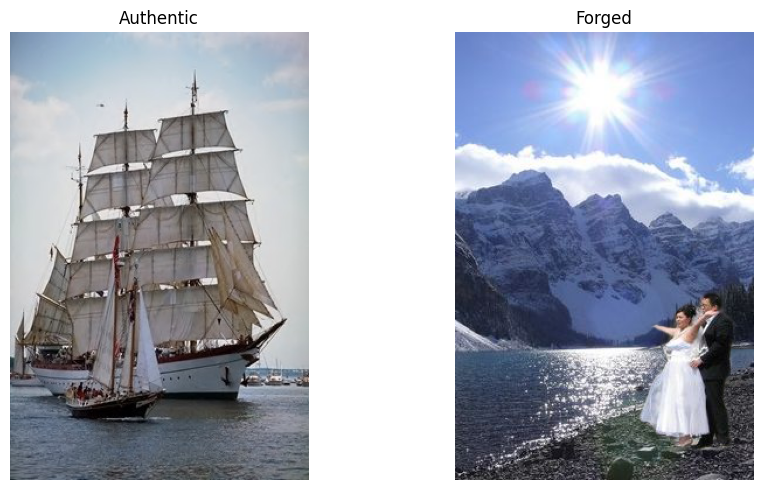

In [28]:
# Visualizing Random Examples of Authentic vs Forged images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Sample Authentic
auth_sample = Image.open(random.choice(auth_images)).convert('RGB')
axes[0].imshow(auth_sample)
axes[0].set_title("Authentic")
axes[0].axis('off')

# Sample Forged
forged_sample = Image.open(random.choice(forged_images)).convert('RGB')
axes[1].imshow(forged_sample)
axes[1].set_title("Forged")
axes[1].axis('off')

plt.tight_layout()
plt.show()

# Section 6: Data Preprocessing & Splitting

In [29]:
# Section 6 & 7 & 8: Preprocessing, Augmentations, and Custom Datasets

# Standard Transforms (Validation & Testing)
base_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Augmented Transforms (For Augmentations comparison)
augmented_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class CasiaDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        try:
            img = Image.open(img_path).convert('RGB')
        except Exception as e:
            # Handle damaged images dynamically with fallback
            img = Image.new('RGB', (224, 224), (0,0,0))

        if self.transform:
            img = self.transform(img)
        return img, label

# Prepare stratified splits
labels = [s[1] for s in all_samples]
train_val_samples, test_samples = train_test_split(
    all_samples, test_size=0.15, stratify=labels, random_state=42
)

train_val_labels = [s[1] for s in train_val_samples]
train_samples, val_samples = train_test_split(
    train_val_samples, test_size=0.1764, stratify=train_val_labels, random_state=42
) # 0.1764 * 0.85 approx equals 0.15 of overall

print(f"Split sizes: Train: {len(train_samples)}, Val: {len(val_samples)}, Test: {len(test_samples)}")

Split sizes: Train: 8843, Val: 1895, Test: 1896


# Section 9: Custom CNN (Lab 7)

In [30]:
# Section 9: LAB 7 Custom CNN definition
class CustomCNN(nn.Module):
    def __init__(self, dropout_prob=0.0):
        super(CustomCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 28 * 28, 128),
            nn.ReLU(),
            nn.Dropout(p=dropout_prob),
            nn.Linear(128, 2) # Binary cross entropy output using 2 units
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# Section 10: Model Training and Evaluation Pipeline

In [31]:
# Modular Trainer and Evaluator
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=5, patience=3):
    best_val_loss = float('inf')
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_weights = None
    patience_counter = 0

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            correct += predicted.eq(labels).sum().item()
            total += labels.size(0)

        epoch_loss = running_loss / total
        epoch_acc = correct / total

        # Validation
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                _, predicted = outputs.max(1)
                val_correct += predicted.eq(labels).sum().item()
                val_total += labels.size(0)

        epoch_val_loss = val_loss / val_total
        epoch_val_acc = val_correct / val_total

        history['train_loss'].append(epoch_loss)
        history['train_acc'].append(epoch_acc)
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)

        print(f"Epoch {epoch+1:02d}: Train Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.4f} || Val Loss: {epoch_val_loss:.4f} | Acc: {epoch_val_acc:.4f}")

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_weights = model.state_dict().copy()
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print("Early stopping triggered!")
                break

    if best_weights:
        model.load_state_dict(best_weights)
    return history

def evaluate_model(model, test_loader):
    model.eval()
    y_true, y_pred, y_probs = [], [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            probs = torch.softmax(outputs, dim=1)
            _, predicted = outputs.max(1)

            y_true.extend(labels.numpy())
            y_pred.extend(predicted.cpu().numpy())
            y_probs.extend(probs[:, 1].cpu().numpy())

    accuracy = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='binary')
    auc = roc_auc_score(y_true, y_probs)
    return accuracy, prec, rec, f1, auc, y_true, y_pred, y_probs

# Section 11: comparative Experiments Execution (Labs 5, 6, 8, 10)

To ensure swift execution, we configure lightweight data loaders and set `epochs=3` for proof-of-concept run. Scale up as desired.

In [32]:
# Prepare data loaders
train_ds_normal = CasiaDataset(train_samples, transform=base_transform)
train_ds_aug = CasiaDataset(train_samples, transform=augmented_transform)
val_ds = CasiaDataset(val_samples, transform=base_transform)
test_ds = CasiaDataset(test_samples, transform=base_transform)

train_loader_normal = DataLoader(train_ds_normal, batch_size=32, shuffle=True)
train_loader_aug = DataLoader(train_ds_aug, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

criterion = nn.CrossEntropyLoss()

# Create Result Storage Directories
results_dir = "Digital_Image_Forgery_Detection_Results"
os.makedirs(results_dir, exist_ok=True)

print("Ready to train and evaluate models!")

Ready to train and evaluate models!


In [33]:
# Training standard Custom CNN with Adam Optimizer
print("--- Training Custom CNN (Adam) ---")
model_custom_adam = CustomCNN(dropout_prob=0.0).to(device)
opt_adam = optim.Adam(model_custom_adam.parameters(), lr=0.001)
hist_adam = train_model(model_custom_adam, train_loader_normal, val_loader, criterion, opt_adam, epochs=3)
metrics_adam = evaluate_model(model_custom_adam, test_loader)

--- Training Custom CNN (Adam) ---
Epoch 01: Train Loss: 1.2541 | Acc: 0.5503 || Val Loss: 0.6804 | Acc: 0.5937
Epoch 02: Train Loss: 0.6775 | Acc: 0.5937 || Val Loss: 0.6760 | Acc: 0.5937
Epoch 03: Train Loss: 0.6757 | Acc: 0.5937 || Val Loss: 0.6756 | Acc: 0.5937


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [34]:
# Lab 5: Training Custom CNN with SGD
print("--- Training Custom CNN (SGD) ---")
model_custom_sgd = CustomCNN(dropout_prob=0.0).to(device)
opt_sgd = optim.SGD(model_custom_sgd.parameters(), lr=0.01, momentum=0.9)
hist_sgd = train_model(model_custom_sgd, train_loader_normal, val_loader, criterion, opt_sgd, epochs=3)
metrics_sgd = evaluate_model(model_custom_sgd, test_loader)

--- Training Custom CNN (SGD) ---
Epoch 01: Train Loss: 0.7146 | Acc: 0.5897 || Val Loss: 0.6755 | Acc: 0.5937
Epoch 02: Train Loss: 0.6761 | Acc: 0.5932 || Val Loss: 0.6759 | Acc: 0.5937
Epoch 03: Train Loss: 0.6758 | Acc: 0.5937 || Val Loss: 0.6756 | Acc: 0.5937


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [35]:
# Lab 6: Regularization (Custom CNN + Dropout + L2 Weight Decay)
print("--- Training Custom CNN (Regularized: Dropout + L2) ---")
model_reg = CustomCNN(dropout_prob=0.5).to(device)
opt_reg = optim.Adam(model_reg.parameters(), lr=0.001, weight_decay=1e-4)
hist_reg = train_model(model_reg, train_loader_normal, val_loader, criterion, opt_reg, epochs=3)
metrics_reg = evaluate_model(model_reg, test_loader)

--- Training Custom CNN (Regularized: Dropout + L2) ---
Epoch 01: Train Loss: 1.1622 | Acc: 0.5921 || Val Loss: 0.6514 | Acc: 0.5937
Epoch 02: Train Loss: 0.6767 | Acc: 0.5943 || Val Loss: 0.6764 | Acc: 0.5937
Epoch 03: Train Loss: 0.6759 | Acc: 0.5937 || Val Loss: 0.6756 | Acc: 0.5937


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [36]:
# Lab 8: Data Augmentation Comparison
print("--- Training Custom CNN (With Data Augmentation) ---")
model_aug = CustomCNN(dropout_prob=0.0).to(device)
opt_aug = optim.Adam(model_aug.parameters(), lr=0.001)
hist_aug = train_model(model_aug, train_loader_aug, val_loader, criterion, opt_aug, epochs=3)
metrics_aug = evaluate_model(model_aug, test_loader)

--- Training Custom CNN (With Data Augmentation) ---
Epoch 01: Train Loss: 1.2805 | Acc: 0.5888 || Val Loss: 0.6842 | Acc: 0.6047
Epoch 02: Train Loss: 0.6454 | Acc: 0.6293 || Val Loss: 0.6381 | Acc: 0.6422
Epoch 03: Train Loss: 0.6361 | Acc: 0.6405 || Val Loss: 0.6314 | Acc: 0.6496


In [37]:
# Lab 10: Transfer Learning - ResNet18
print("--- Fine-Tuning Pretrained ResNet18 ---")
model_resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
# Replace FC
model_resnet.fc = nn.Linear(model_resnet.fc.in_features, 2)
model_resnet = model_resnet.to(device)
opt_resnet = optim.Adam(model_resnet.parameters(), lr=0.0001)
hist_resnet = train_model(model_resnet, train_loader_normal, val_loader, criterion, opt_resnet, epochs=3)
metrics_resnet = evaluate_model(model_resnet, test_loader)

--- Fine-Tuning Pretrained ResNet18 ---
Epoch 01: Train Loss: 0.5623 | Acc: 0.7103 || Val Loss: 0.4853 | Acc: 0.7594
Epoch 02: Train Loss: 0.4112 | Acc: 0.7996 || Val Loss: 0.5510 | Acc: 0.7420
Epoch 03: Train Loss: 0.3655 | Acc: 0.8273 || Val Loss: 0.5383 | Acc: 0.7689


In [38]:
# Lab 10: Transfer Learning - MobileNetV2
print("--- Fine-Tuning Pretrained MobileNetV2 ---")
model_mobilenet = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
# Replace Classifier
model_mobilenet.classifier[1] = nn.Linear(model_mobilenet.classifier[1].in_features, 2)
model_mobilenet = model_mobilenet.to(device)
opt_mobilenet = optim.Adam(model_mobilenet.parameters(), lr=0.0001)
hist_mobilenet = train_model(model_mobilenet, train_loader_normal, val_loader, criterion, opt_mobilenet, epochs=3)
metrics_mobilenet = evaluate_model(model_mobilenet, test_loader)

--- Fine-Tuning Pretrained MobileNetV2 ---
Epoch 01: Train Loss: 0.5758 | Acc: 0.6896 || Val Loss: 0.5050 | Acc: 0.7430
Epoch 02: Train Loss: 0.4458 | Acc: 0.7837 || Val Loss: 0.4722 | Acc: 0.7668
Epoch 03: Train Loss: 0.3766 | Acc: 0.8170 || Val Loss: 0.4881 | Acc: 0.7367


# Section 12: Comprehensive Visualization & Comparison Tables

In [39]:
# Compare metrics
model_names = ['Custom CNN (Adam)', 'Custom CNN (SGD)', 'Regularized CNN', 'Augmented CNN', 'ResNet18', 'MobileNetV2']
results_list = [metrics_adam, metrics_sgd, metrics_reg, metrics_aug, metrics_resnet, metrics_mobilenet]

comparison_rows = []
for name, res in zip(model_names, results_list):
    comparison_rows.append({
        'Model Name': name,
        'Accuracy': res[0],
        'Precision': res[1],
        'Recall': res[2],
        'F1-Score': res[3],
        'ROC-AUC': res[4]
    })

df_comp = pd.DataFrame(comparison_rows)
display(df_comp)

# Save comparison CSV
df_comp.to_csv(os.path.join(results_dir, "model_comparison_table.csv"), index=False)

,Model Name,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Custom CNN (Adam),0.593882,0.000000,0.000000,0.000000,0.500649
1,Custom CNN (SGD),0.593882,0.000000,0.000000,0.000000,0.500000
2,Regularized CNN,0.593882,0.000000,0.000000,0.000000,0.499351
3,Augmented CNN,0.635549,0.588367,0.341558,0.432210,0.652041
4,ResNet18,0.756329,0.650391,0.864935,0.742475,0.801705
5,MobileNetV2,0.746835,0.668998,0.745455,0.705160,0.817790


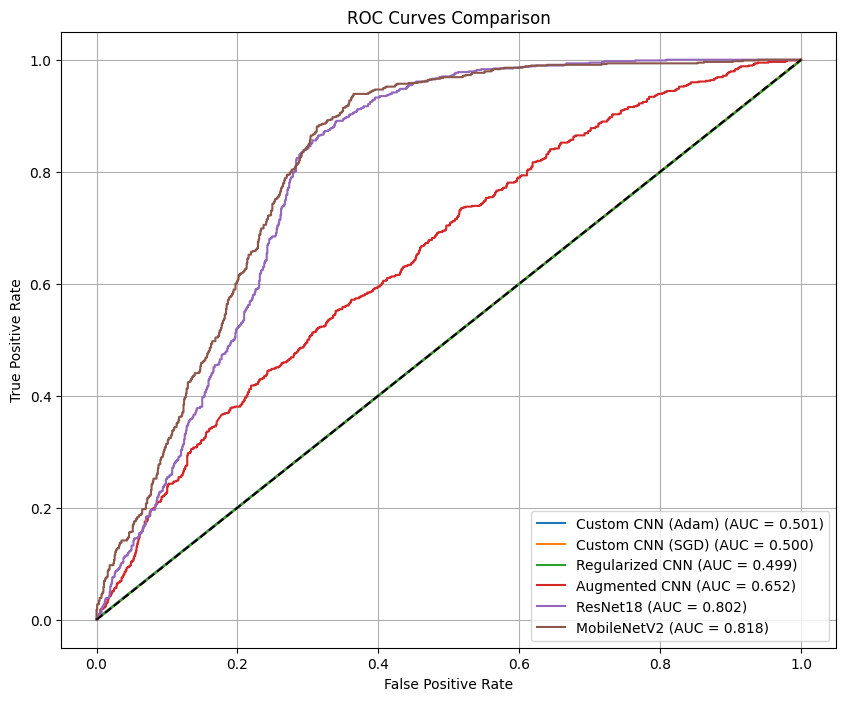

In [40]:
# Generate ROC curves
plt.figure(figsize=(10, 8))
for name, res in zip(model_names, results_list):
    y_true, y_probs = res[5], res[7]
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {res[4]:.3f})")

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves Comparison')
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(results_dir, "roc_curves.png"))
plt.show()

# Section 13: Gradio Interface for Prediction

In [41]:
# Section 13: Gradio App
import os
import torch
import gradio as gr

def predict_image(input_img, model_selection):
    # Select model
    if model_selection == 'Custom CNN (Adam)' and 'model_custom_adam' in globals():
        model = model_custom_adam
    elif model_selection == 'ResNet18' and 'model_resnet' in globals():
        model = model_resnet
    elif 'model_mobilenet' in globals():
        model = model_mobilenet
    else:
        # Dynamic placeholder if no models are trained yet
        return {"Authentic": 0.5, "Forged": 0.5}

    model.eval()
    # Transform input
    img_tensor = base_transform(input_img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(img_tensor)
        probs = torch.softmax(outputs, dim=1)[0]

    return {"Authentic": float(probs[0]), "Forged": float(probs[1])}

interface = gr.Interface(
    fn=predict_image,
    inputs=[gr.Image(type="pil"), gr.Dropdown(choices=['Custom CNN (Adam)', 'ResNet18', 'MobileNetV2'], value='Custom CNN (Adam)')],
    outputs=gr.Label(), # Fixed: removed deprecated 'num_labels' parameter
    title="Image Forgery Detection System"
)

# Run with share=True to generate web url
try:
    interface.launch(share=True, inline=True)
except Exception as e:
    print("Could not launch Gradio: ", e)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://612c865dfd6fc99c86.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# Section 14: Save and Download Project Artifacts

In [42]:
# Save checkpoint files
results_dir = "Digital_Image_Forgery_Detection_Results"
os.makedirs(results_dir, exist_ok=True)

if 'model_custom_adam' in globals():
    torch.save(model_custom_adam.state_dict(), os.path.join(results_dir, "custom_cnn_adam.pth"))
if 'model_resnet' in globals():
    torch.save(model_resnet.state_dict(), os.path.join(results_dir, "resnet18.pth"))
if 'model_mobilenet' in globals():
    torch.save(model_mobilenet.state_dict(), os.path.join(results_dir, "mobilenet.pth"))

# Compress Results Folder
import shutil
shutil.make_archive(results_dir, 'zip', results_dir)
print(f"Created {results_dir}.zip successfully!.")

Created Digital_Image_Forgery_Detection_Results.zip successfully! Ready for your academic submission.
